In [1]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt

In [2]:
# 1. 데이터 불러오기
iris = load_iris()
print(iris.keys())
x = iris.data
y = iris.target

# 2. 데이터 분리
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.7, random_state=555, stratify=y)

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])


In [3]:
# 3. 알코리즘 선택
# max_depth=3 - 가지가 벋어 나가는 단계 제한(max_depth 가 없으면 계속 아래로 내려가면서 가지가 많아져 과대적합이 생길수 있다.)
tree = DecisionTreeClassifier(max_depth=3).fit(x_train,y_train)

print(f'train score : {tree.score(x_train,y_train):.2f}')
print(f'test score : {tree.score(x_test,y_test):.2f}')

train score : 1.00
test score : 0.93


In [ ]:
# 4. tree 가 어떻게 그려졌는가?
from sklearn.tree import export_graphviz


src = export_graphviz(tree, # 사용한 tree 모델
  out_file= None, # 파일을 밖으로 내보낼때, 내보내지 않으려면 None
  class_names=iris.target_names, # 각 분류에 표기할 이름 지정
  feature_names=iris.feature_names, # 각 특성에 표기될 이름
  impurity=False,  # 지니계수 표출 여부(지니계수가 낮을 수록 분류가 잘 된것으로 판단)
  filled=True)    # 표에 색상을 채울지 여부

print(src)
# https://dreampuf.github.io/GraphvizOnline

digraph Tree {
node [shape=box, style="filled", color="black", fontname="helvetica"] ;
edge [fontname="helvetica"] ;
0 [label="petal length (cm) <= 2.6\nsamples = 45\nvalue = [15, 15, 15]\nclass = setosa", fillcolor="#ffffff"] ;
1 [label="samples = 15\nvalue = [15, 0, 0]\nclass = setosa", fillcolor="#e58139"] ;
0 -> 1 [labeldistance=2.5, labelangle=45, headlabel="True"] ;
2 [label="petal length (cm) <= 4.8\nsamples = 30\nvalue = [0, 15, 15]\nclass = versicolor", fillcolor="#ffffff"] ;
0 -> 2 [labeldistance=2.5, labelangle=-45, headlabel="False"] ;
3 [label="samples = 15\nvalue = [0, 15, 0]\nclass = versicolor", fillcolor="#39e581"] ;
2 -> 3 ;
4 [label="samples = 15\nvalue = [0, 0, 15]\nclass = virginica", fillcolor="#8139e5"] ;
2 -> 4 ;
}


In [4]:
# 5. 어떤 특성이 중요도가 높은가?(모든 특성의 합은 1이 된다.)
print(f'특성 명 : {iris.feature_names}')
print(f'특성 중요도 : {tree.feature_importances_}')

특성 명 : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
특성 중요도 : [0. 0. 1. 0.]


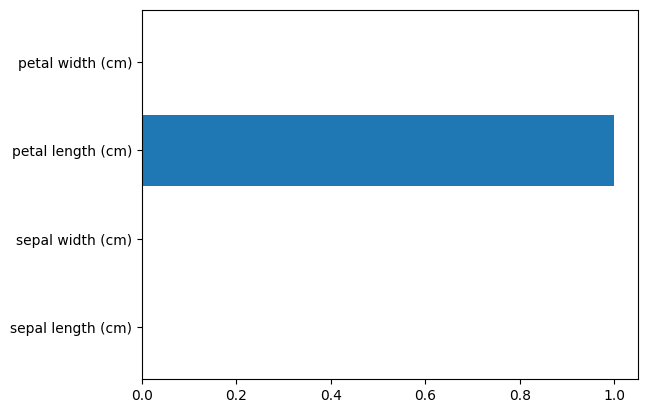

In [5]:
# 그래프로 어떤 특성을 많이 사용했는지 그려보자
plt.barh(iris.feature_names, tree.feature_importances_)
plt.show()
# feature_importances_ 에서 선택되지 않았다고 해당 특성이 유용하지 않다는 뜻은 아니다.
# 트리가 그 특성을 선택하지 않았을 뿐이며 다른 특성이 동일한 정보를 지니고 있어서일 수도 있다.